## Imports

In [1]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from utils.config_loader import load_config_yaml
from pathlib import Path

In [2]:
config = load_config_yaml("base.yaml")
data_folder = Path(config["data"]["path_to_data"])

print("Configured data folder:", data_folder.resolve())
print("Data folder exists:", data_folder.exists())

DATA_ROOT = data_folder

print("RegulaTome folder:", DATA_ROOT.resolve())
print("RegulaTome folder exists:", DATA_ROOT.exists())

Configured data folder: C:\Users\agardzielewska\WORK\test\Graph-Extraction\data
Data folder exists: True
RegulaTome folder: C:\Users\agardzielewska\WORK\test\Graph-Extraction\data
RegulaTome folder exists: True


## File information

In [3]:
ann_files = sorted(DATA_ROOT.rglob("*.ann"))
txt_files = sorted(DATA_ROOT.rglob("*.txt"))

print("Annotation files:", len(ann_files))
print("Text files:", len(txt_files))

if DATA_ROOT.exists():
    print("\nContents:")
    for path in DATA_ROOT.iterdir():
        print(path.name)

if not ann_files:
    raise FileNotFoundError(
        "No .ann files found. Check DATA_ROOT and the extracted dataset."
    )
print(f".ann files: {len(ann_files)}")
print(f".txt files: {len(txt_files)}")

Annotation files: 2522
Text files: 2522

Contents:
plots
RegulaTome-corpus
.ann files: 2522
.txt files: 2522


In [4]:
def get_split(path: Path) -> str:
    rel = path.relative_to(DATA_ROOT)
    return rel.parts[0] if len(rel.parts) > 1 else "root"

def parse_ann(ann_path: Path):
    """Parse a BRAT .ann file into entities, relations, events, attributes, normalizations."""
    entities, relations, events, attributes, norms = [], [], [], [], []

    with open(ann_path, encoding="utf-8") as f:
        for line in f:
            line = line.rstrip("\n")
            if not line.strip():
                continue
            parts = line.split("\t")
            idx = parts[0]
            kind = idx[0]

            try:
                if kind == "T":
                    type_and_spans = parts[1]
                    text = parts[2] if len(parts) > 2 else ""
                    etype, spans = type_and_spans.split(" ", 1)
                    span_list = [tuple(map(int, s.split())) for s in spans.split(";")]
                    entities.append({
                        "ent_id": idx,
                        "type": etype,
                        "start": span_list[0][0],
                        "end": span_list[-1][1],
                        "n_fragments": len(span_list),
                        "text": text,
                    })
                elif kind == "R":
                    fields = parts[1].split()
                    rtype = fields[0]
                    args = dict(a.split(":", 1) for a in fields[1:])
                    relations.append({"rel_id": idx, "type": rtype, **args})
                elif kind == "E":
                    events.append({"event_id": idx, "raw": parts[1]})
                elif kind == "A" or kind == "M":
                    fields = parts[1].split()
                    attributes.append({
                        "attr_id": idx,
                        "name": fields[0],
                        "target": fields[1] if len(fields) > 1 else None,
                        "value": fields[2] if len(fields) > 2 else None,
                    })
                elif kind == "N":
                    norms.append({"norm_id": idx, "raw": parts[1], "text": parts[2] if len(parts) > 2 else ""})
            except Exception as e:  # keep going on odd lines, but report
                print(f"[WARN] {ann_path.name}: could not parse line: {line!r} ({e})")

    return entities, relations, events, attributes, norms
doc_rows, ent_rows, rel_rows, evt_rows, attr_rows, norm_rows = [], [], [], [], [], []

for ann_path in ann_files:
    doc_id = ann_path.stem
    split = get_split(ann_path)
    txt_path = ann_path.with_suffix(".txt")
    text = txt_path.read_text(encoding="utf-8") if txt_path.exists() else ""

    ents, rels, evts, attrs, norms = parse_ann(ann_path)

    doc_rows.append({
        "doc_id": doc_id,
        "split": split,
        "n_chars": len(text),
        "n_words": len(text.split()),
        "n_entities": len(ents),
        "n_relations": len(rels),
        "n_events": len(evts),
        "n_attributes": len(attrs),
        "text": text,
    })
    for e in ents:
        ent_rows.append({"doc_id": doc_id, "split": split, **e})
    for r in rels:
        rel_rows.append({"doc_id": doc_id, "split": split, **r})
    for a in attrs:
        attr_rows.append({"doc_id": doc_id, "split": split, **a})
    for n in norms:
        norm_rows.append({"doc_id": doc_id, "split": split, **n})
    for ev in evts:
        evt_rows.append({"doc_id": doc_id, "split": split, **ev})

docs = pd.DataFrame(doc_rows)
ents = pd.DataFrame(ent_rows)
rels = pd.DataFrame(rel_rows)
attrs = pd.DataFrame(attr_rows)
norms = pd.DataFrame(norm_rows)
events = pd.DataFrame(evt_rows)

print(f"docs={len(docs)}  entities={len(ents)}  relations={len(rels)}  "
      f"events={len(events)}  attributes={len(attrs)}  normalizations={len(norms)}")


docs=2522  entities=58114  relations=19374  events=0  attributes=6650  normalizations=0


# EDA

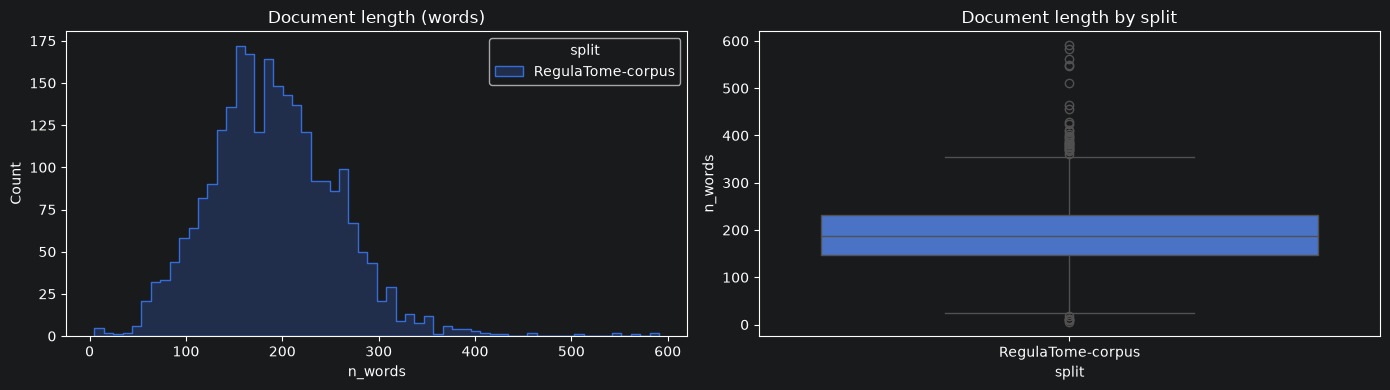

,n_chars,n_words
count,2522.0,2522.0
mean,1324.5,191.0
std,456.4,66.6
min,63.0,5.0
5%,599.1,89.0
25%,1017.2,147.0
50%,1304.0,187.0
75%,1617.0,232.0
95%,2069.8,296.0
99%,2447.3,371.8


In [5]:
fig, axes = plt.subplots(1, 2, figsize=(14, 4))
sns.histplot(data=docs, x="n_words", hue="split", bins=60, element="step", ax=axes[0])
axes[0].set_title("Document length (words)")
sns.boxplot(data=docs, x="split", y="n_words", ax=axes[1])
axes[1].set_title("Document length by split")
plt.tight_layout()
plt.show()

docs[["n_chars", "n_words"]].describe(percentiles=[.05, .25, .5, .75, .95, .99]).round(1)


In [6]:
ents["length_chars"] = ents["end"] - ents["start"]
ents["length_words"] = ents["text"].str.split().str.len()

ent_type_counts = ents.groupby(["split", "type"]).size().unstack(0, fill_value=0)
ent_type_counts.sort_values("RegulaTome-corpus", ascending=False)

split,RegulaTome-corpus
type,
Protein,38949
Family,7480
Chemical,4706
Complex,3846
OOS,3133


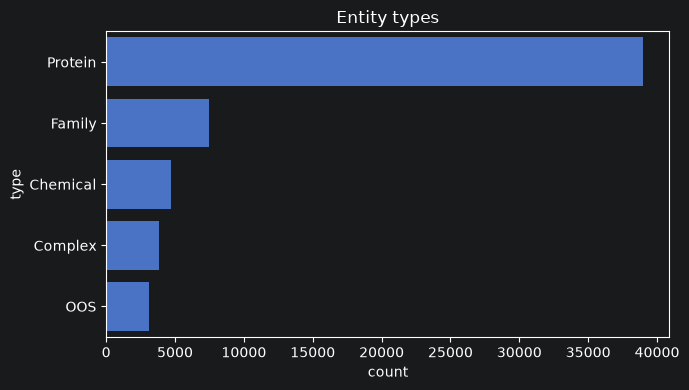

In [7]:
fig, ax = plt.subplots(1, 1, figsize=(7, 4))

order = ents["type"].value_counts().index
sns.countplot(data=ents, y="type", order=order, ax=ax)
ax.set_title("Entity types")

plt.tight_layout()
plt.show()

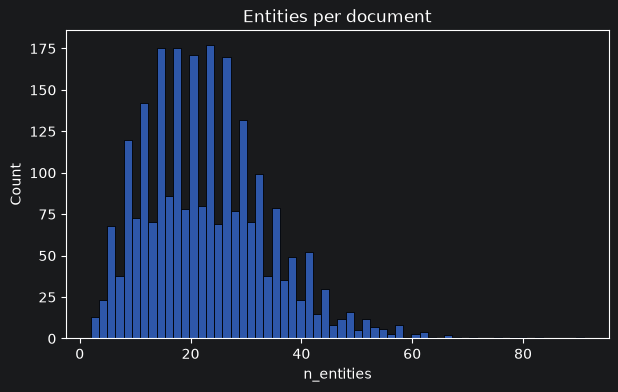

Discontinuous entities: 0 (0.00%)


In [8]:
fig, ax = plt.subplots(figsize=(7, 4))
sns.histplot(data=docs, x="n_entities", bins=60, ax=ax)
ax.set_title("Entities per document")
plt.show()

# Discontinuous mentions
print("Discontinuous entities:", (ents["n_fragments"] > 1).sum(),
      f"({(ents['n_fragments'] > 1).mean():.2%})")


In [9]:
# Most frequent surface forms (lowercased), per type
ents["text_norm"] = ents["text"].str.lower().str.strip()
top_surface = (ents.groupby(["type", "text_norm"]).size()
               .rename("count").reset_index()
               .sort_values("count", ascending=False))
top_surface.groupby("type").head(10).reset_index(drop=True)

,type,text_norm,count
0,Protein,ubiquitin,593
1,Protein,p53,354
2,Family,histone,267
3,Complex,nf-kappab,239
4,Family,actin,175
5,Family,ras,174
6,Family,sumo,169
7,Family,wnt,162
8,Complex,nf-kappa b,140
9,Protein,nedd8,134


In [10]:
# Lexical diversity: unique surface forms vs. mentions
div = ents.groupby("type").agg(mentions=("text_norm", "size"), unique_forms=("text_norm", "nunique"))
div["unique_ratio"] = (div["unique_forms"] / div["mentions"]).round(3)
div

,mentions,unique_forms,unique_ratio
type,,,
Chemical,4706,1329,0.282
Complex,3846,746,0.194
Family,7480,1636,0.219
OOS,3133,1652,0.527
Protein,38949,8205,0.211


In [11]:
print("Relation columns:", list(rels.columns))
arg_cols = [c for c in rels.columns if c.lower().startswith("arg")]
print("Argument columns:", arg_cols)

rel_type_counts = rels.groupby(["split", "type"]).size().unstack(0, fill_value=0)
rel_type_counts.sort_values("RegulaTome-corpus", ascending=False)

Relation columns: ['doc_id', 'split', 'rel_id', 'type', 'Arg1', 'Arg2']
Argument columns: ['Arg1', 'Arg2']


split,RegulaTome-corpus
type,
Complex_formation,6463
Out-of-scope,2399
Regulation,2294
Positive_regulation,2133
Negative_regulation,1920
Regulation_of_transcription,899
Regulation_of_gene_expression,521
Catalysis_of_ubiquitination,474
Catalysis_of_phosphorylation,442


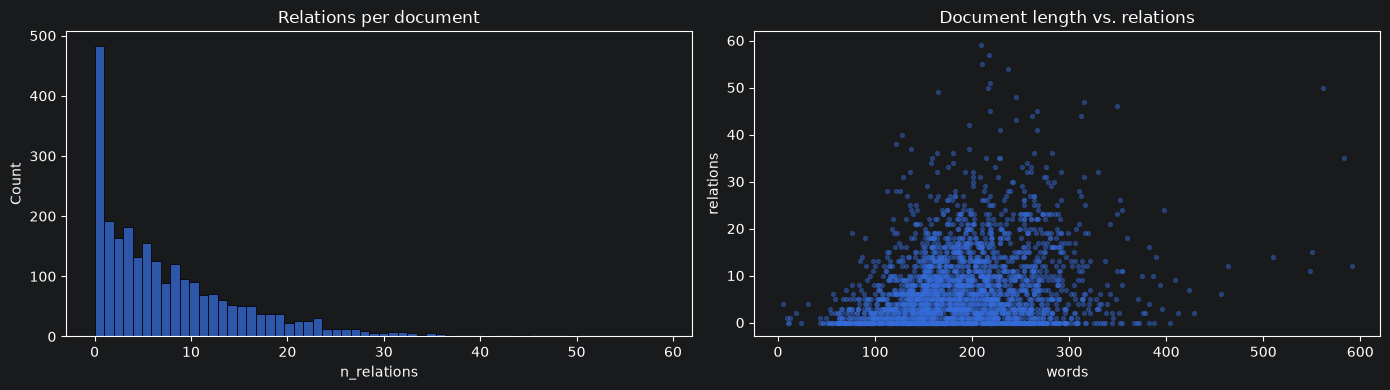

In [12]:
# Relations per document
fig, axes = plt.subplots(1, 2, figsize=(14, 4))
sns.histplot(data=docs, x="n_relations", bins=60, ax=axes[0])
axes[0].set_title("Relations per document")
axes[1].scatter(docs["n_words"], docs["n_relations"], s=8, alpha=0.4)
axes[1].set_xlabel("words"); axes[1].set_ylabel("relations")
axes[1].set_title("Document length vs. relations")
plt.tight_layout()
plt.show()